# Modeling notebook

Here I will load the data, do the feature engineering (keep only the variables I want to predict on), split the train data into a smaller train set (years 2009–2016) and a validation set (2017) and create and test the models.

In [1]:
import pandas as pd
import numpy as np
from pathlib import Path
from sklearn.metrics import root_mean_squared_error, mean_absolute_error
from sklearn.linear_model import LinearRegression
import matplotlib.pyplot as plt

RAW_DATA_PATH = Path("..") / "data" / "raw_data"

# importing the train data
train_raw = pd.read_csv(RAW_DATA_PATH / "train.csv")

In [2]:
# here I'm creating the time index
# also dopping the Year, Month, Day, Hour, Minute columns as I won't use them for modeling
def time_index_creation(df):
    df = df.copy()
    df.index = pd.to_datetime({'year': df['Year'],
                                      'month': df['Month'],
                                      'day': df['Day'],
                                      'hour': df['Hour'],
                                      'minute': df['Minute']})
    return df

train_indexed = time_index_creation(train_raw)
train_indexed.head(3)

,Year,Month,Day,Hour,Minute,ClearskyDHI,ClearskyDNI,ClearskyGHI,Cloud Type,Dew Point,Temperature,Pressure,Relative Humidity,Solar Zenith Angle,Precipitable Water,Wind Direction,Wind Speed,Fill Flag
2009-01-01 00:00:00,2009,1,1,0,0,0,0,0,0,0,5,1010,75.34,106.15,0.499,346.1,3.1,0
2009-01-01 00:30:00,2009,1,1,0,30,0,0,0,0,1,5,1010,80.81,112.28,0.490,346.1,3.1,0
2009-01-01 01:00:00,2009,1,1,1,0,0,0,0,4,0,5,1010,78.27,118.50,0.482,347.9,3.2,0


## Spliting the train data into a train and validation set
- here I will split the data into a train and a validation set
- on the train set I will train the model and the validation set I will use to compute the model metrics (how good the model is)
- I can then use the informations gained to compare and adjust the models

In [3]:
SPLIT_DATE = '2017-01-01'

train = train_indexed[train_indexed.index < SPLIT_DATE]
val = train_indexed[train_indexed.index < SPLIT_DATE]

print(f'train: {train.index.min()}   {train.index.max()}')
print(f'val: {val.index.min()}   {val.index.max()}')

train: 2009-01-01 00:00:00   2016-12-31 23:30:00
val: 2009-01-01 00:00:00   2016-12-31 23:30:00


## Baseline Model Creation
- here I'll create a baseline model to set a benchmark for the next models to beat
- it will just predict a mean of all the values from the same month and time

In [4]:
TARGETS = ['ClearskyGHI', 'ClearskyDNI', 'ClearskyDHI']
TIME_KEYS = ["month", "time"]

def add_time_keys(df):
    output = df.copy()
    output["month"] = output.index.month
    output["time"] = output.index.time
    return output

train_with_time = add_time_keys(train)
val_with_time = add_time_keys(val)

# now I'll create a table that contains for each month and each time the mean of the targets from train set
train_averages = train_with_time.groupby(TIME_KEYS)[TARGETS].mean()

baseline_prediction = val_with_time[TIME_KEYS].join(train_averages, on=TIME_KEYS)

Now I'm gonna evaluate the baseline model and store the results.

I'm gonna use a RMSE and MAE. If RMSE will be much higher than MAE it's caused by some huge errors.

In [5]:
results = []

def evaluate_model(model_name, target_name, y_true, y_pred):
    results.append({"model": model_name,
                    "target": target_name,
                    "rmse": root_mean_squared_error(y_true, y_pred),
                    "mae": mean_absolute_error(y_true, y_pred)})
    


In [6]:
# evaluate the baseline
for t in TARGETS:
    evaluate_model("baseline", t, val[t], baseline_prediction[t])

In [7]:
def add_features(df):
    df = df.copy()  
    df['cos_zenith'] = np.cos(np.radians(df['Solar Zenith Angle']))
    df['is_day'] = np.where(df['Solar Zenith Angle'] < 90, True, False)
    df['cos_x_PW'] = df['cos_zenith'] * df['Precipitable Water']
    df['month'] = df.index.month
    df['hour'] = df.index.hour
    df['minute'] = df.index.minute
    return df

train = add_features(train)
val = add_features(val)
    

In [8]:
train_day = train['is_day']
val_day = val['is_day']

FEATURES_1 = ['cos_zenith']

for target in TARGETS:
    model = LinearRegression()
    model.fit(train.loc[train_day, FEATURES_1], train.loc[train_day, target])
    
    pred = pd.Series(0.0, index=val.index)
    pred.loc[val_day] = model.predict(val.loc[val_day, FEATURES_1])
    pred = pred.clip(lower=0)
    
    evaluate_model("linreg_cos", target, val[target], pred)

In [9]:
FEATURES_2 = ['cos_zenith', 'Precipitable Water']

for target in TARGETS:
    model = LinearRegression()
    model.fit(train.loc[train_day, FEATURES_2], train.loc[train_day, target])
    
    pred = pd.Series(0.0, index=val.index)
    pred.loc[val_day] = model.predict(val.loc[val_day, FEATURES_2])
    pred = pred.clip(lower=0)
    
    evaluate_model("linreg_cos_PrecWater", target, val[target], pred)

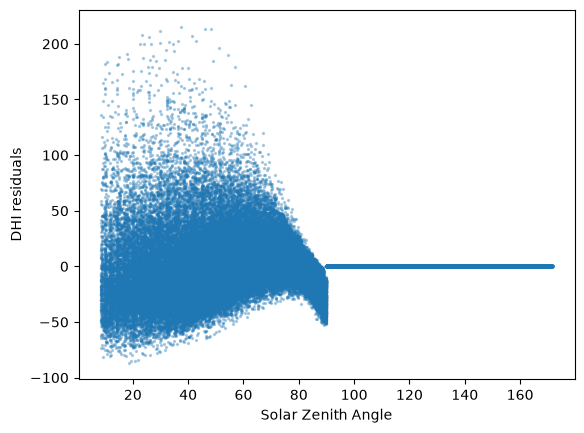

In [10]:
residuals = val['ClearskyDHI']-pred
plt.scatter(val['Solar Zenith Angle'], residuals, s=2, alpha=0.3)
plt.xlabel('Solar Zenith Angle')
plt.ylabel('DHI residuals')
plt.show()

In [11]:
FEATURES_3 = ['cos_zenith', 'Precipitable Water', 'cos_x_PW']

for target in TARGETS:
    model = LinearRegression()
    model.fit(train.loc[train_day, FEATURES_3], train.loc[train_day, target])
    
    pred = pd.Series(0.0, index=val.index)
    pred.loc[val_day] = model.predict(val.loc[val_day, FEATURES_3])
    pred = pred.clip(lower=0)
    
    evaluate_model("linreg_cos_PrecWater_cosxPW", target, val[target], pred)

## Random Forest

In [12]:
from sklearn.ensemble import RandomForestRegressor



for target in TARGETS:
    model = RandomForestRegressor(
    n_estimators=100,      # number of trees
    min_samples_leaf=10,   # each leaf must contain at least 10 rows
    n_jobs=-1,             # use all CPU cores
    random_state=42,       # reproducible results
    )
    model.fit(train.loc[train_day, FEATURES_2], train.loc[train_day, target])
    
    pred = pd.Series(0.0, index=val.index)
    pred.loc[val_day] = model.predict(val.loc[val_day, FEATURES_2])
    pred = pred.clip(lower=0)
    
    evaluate_model("random_forest_10_leaf", target, val[target], pred)


In [13]:
for target in TARGETS:
    model = RandomForestRegressor(
    n_estimators=100,      # number of trees
    min_samples_leaf=1,   # each leaf must contain at least 10 rows
    n_jobs=-1,             # use all CPU cores
    random_state=42,       # reproducible results
    )
    model.fit(train.loc[train_day, FEATURES_2], train.loc[train_day, target])
    
    pred = pd.Series(0.0, index=val.index)
    pred.loc[val_day] = model.predict(val.loc[val_day, FEATURES_2])
    pred = pred.clip(lower=0)
    
    evaluate_model("random_forest_1_leaf", target, val[target], pred)

In [14]:
for target in TARGETS:
    model = RandomForestRegressor(
    n_estimators=100,      # number of trees
    min_samples_leaf=50,   # each leaf must contain at least 10 rows
    n_jobs=-1,             # use all CPU cores
    random_state=42,       # reproducible results
    )
    model.fit(train.loc[train_day, FEATURES_2], train.loc[train_day, target])
    
    pred = pd.Series(0.0, index=val.index)
    pred.loc[val_day] = model.predict(val.loc[val_day, FEATURES_2])
    pred = pred.clip(lower=0)
    
    evaluate_model("random_forest_50_leaf", target, val[target], pred)

In [15]:
FEATURES_4 = ['cos_zenith', 'Precipitable Water', 'Relative Humidity']
for target in TARGETS:
    model = RandomForestRegressor(
    n_estimators=100,      # number of trees
    min_samples_leaf=1,   # each leaf must contain at least 10 rows
    n_jobs=-1,             # use all CPU cores
    random_state=42,       # reproducible results
    )
    model.fit(train.loc[train_day, FEATURES_4], train.loc[train_day, target])
    
    pred = pd.Series(0.0, index=val.index)
    pred.loc[val_day] = model.predict(val.loc[val_day, FEATURES_4])
    pred = pred.clip(lower=0)
    
    evaluate_model("random_forest_1_leaf_with_humidity", target, val[target], pred)

In [16]:
FEATURES_5 = ['cos_zenith', 'Precipitable Water', 'Pressure']
for target in TARGETS:
    model = RandomForestRegressor(
    n_estimators=100,      # number of trees
    min_samples_leaf=1,   # each leaf must contain at least 10 rows
    n_jobs=-1,             # use all CPU cores
    random_state=42,       # reproducible results
    )
    model.fit(train.loc[train_day, FEATURES_5], train.loc[train_day, target])
    
    pred = pd.Series(0.0, index=val.index)
    pred.loc[val_day] = model.predict(val.loc[val_day, FEATURES_5])
    pred = pred.clip(lower=0)
    
    evaluate_model("random_forest_1_leaf_with_pressure", target, val[target], pred)

In [17]:
FEATURES_6 = ['cos_zenith', 'Precipitable Water', 'Temperature']
for target in TARGETS:
    model = RandomForestRegressor(
    n_estimators=100,      # number of trees
    min_samples_leaf=1,   # each leaf must contain at least 10 rows
    n_jobs=-1,             # use all CPU cores
    random_state=42,       # reproducible results
    )
    model.fit(train.loc[train_day, FEATURES_6], train.loc[train_day, target])
    
    pred = pd.Series(0.0, index=val.index)
    pred.loc[val_day] = model.predict(val.loc[val_day, FEATURES_6])
    pred = pred.clip(lower=0)
    
    evaluate_model("random_forest_1_leaf_with_Temperature", target, val[target], pred)

In [18]:
FEATURES_7 = ['cos_zenith', 'Precipitable Water', 'month', 'hour', 'minute']
for target in TARGETS:
    model = RandomForestRegressor(
    n_estimators=100,      # number of trees
    min_samples_leaf=1,   # each leaf must contain at least 10 rows
    n_jobs=-1,             # use all CPU cores
    random_state=42,       # reproducible results
    )
    model.fit(train.loc[train_day, FEATURES_7], train.loc[train_day, target])
    
    pred = pd.Series(0.0, index=val.index)
    pred.loc[val_day] = model.predict(val.loc[val_day, FEATURES_7])
    pred = pred.clip(lower=0)
    
    evaluate_model("random_forest_1_leaf_with_month_time", target, val[target], pred)

In [19]:
FEATURES_8 = ['cos_zenith', 'Precipitable Water', 'month', 'hour', 'minute', 'Relative Humidity', 'Temperature']
for target in TARGETS:
    model = RandomForestRegressor(
    n_estimators=100,      # number of trees
    min_samples_leaf=1,   # each leaf must contain at least 10 rows
    n_jobs=-1,             # use all CPU cores
    random_state=42,       # reproducible results
    )
    model.fit(train.loc[train_day, FEATURES_8], train.loc[train_day, target])
    
    pred = pd.Series(0.0, index=val.index)
    pred.loc[val_day] = model.predict(val.loc[val_day, FEATURES_8])
    pred = pred.clip(lower=0)
    
    evaluate_model("random_forest_1_leaf_with_month_time_hum_temp", target, val[target], pred)

<Axes: >

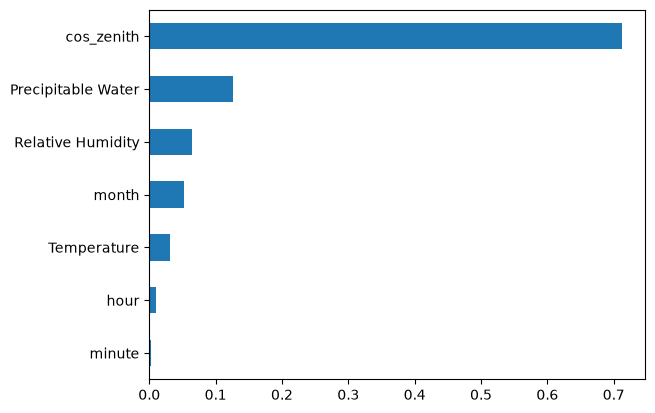

In [20]:
imp = pd.Series(model.feature_importances_, index=FEATURES_8).sort_values()
imp.plot(kind="barh")

In [21]:
results_df = pd.DataFrame(results)
results_df.pivot(index="model", columns="target", values="rmse")
results_df

,model,target,rmse,mae
0,baseline,ClearskyGHI,20.379930,10.960895
1,baseline,ClearskyDNI,56.232951,31.323977
2,baseline,ClearskyDHI,19.208036,9.537031
3,linreg_cos,ClearskyGHI,23.756594,13.438196
4,linreg_cos,ClearskyDNI,102.856436,59.631667
5,linreg_cos,ClearskyDHI,21.239527,11.030756
6,linreg_cos_PrecWater,ClearskyGHI,13.965876,8.048758
7,linreg_cos_PrecWater,ClearskyDNI,77.829280,44.560235
8,linreg_cos_PrecWater,ClearskyDHI,19.859865,10.132665
9,linreg_cos_PrecWater_cosxPW,ClearskyGHI,13.137250,7.496096


In [22]:
test = pd.read_csv(RAW_DATA_PATH/"test.csv")

test_time = time_index_creation(test)
test_with_features = add_features(test_time)






In [23]:


FEATURES_8 = ['cos_zenith', 'Precipitable Water', 'month', 'hour', 'minute', 'Relative Humidity', 'Temperature']
for target in TARGETS:
    model = RandomForestRegressor(
    n_estimators=100,      # number of trees
    min_samples_leaf=1,   # each leaf must contain at least 10 rows
    n_jobs=-1,             # use all CPU cores
    random_state=42,       # reproducible results
    )
    model.fit(train.loc[train_day, FEATURES_8], train.loc[train_day, target])
    
    pred = pd.Series(0.0, index=test_with_features.index)
    pred = model.predict(test_with_features[ FEATURES_8])
    # pred = pred.clip(lower=0)
    
    test_with_features[target] = pred
    
    

In [24]:
test_with_features.head(10)

,Year,Month,Day,Hour,Minute,ClearskyDHI,ClearskyDNI,ClearskyGHI,Cloud Type,Dew Point,...,Precipitable Water,Wind Direction,Wind Speed,Fill Flag,cos_zenith,is_day,cos_x_PW,month,hour,minute
2018-01-01 00:00:00,2018,1,1,0,0,0.0,0.0,0.0,4,1.7,...,1.8,345,2.8,0,-0.278823,False,-0.501882,1,0,0
2018-01-01 00:30:00,2018,1,1,0,30,0.0,0.0,0.0,2,1.7,...,1.8,347,2.8,0,-0.379779,False,-0.683602,1,0,30
2018-01-01 01:00:00,2018,1,1,1,0,0.0,0.0,0.0,0,1.1,...,1.7,349,2.9,0,-0.477772,False,-0.812213,1,1,0
2018-01-01 01:30:00,2018,1,1,1,30,0.0,0.0,0.0,2,1.1,...,1.7,351,2.9,0,-0.571143,False,-0.970944,1,1,30
2018-01-01 02:00:00,2018,1,1,2,0,0.0,0.0,0.0,2,0.7,...,1.6,353,2.8,0,-0.658164,False,-1.053062,1,2,0
2018-01-01 02:30:00,2018,1,1,2,30,0.0,0.0,0.0,2,0.7,...,1.6,354,2.7,0,-0.737513,False,-1.180021,1,2,30
2018-01-01 03:00:00,2018,1,1,3,0,0.0,0.0,0.0,0,0.2,...,1.5,356,2.6,0,-0.807887,False,-1.211831,1,3,0
2018-01-01 03:30:00,2018,1,1,3,30,0.0,0.0,0.0,2,0.2,...,1.5,354,2.7,0,-0.867852,False,-1.301778,1,3,30
2018-01-01 04:00:00,2018,1,1,4,0,0.0,0.0,0.0,0,-0.4,...,1.4,353,2.9,0,-0.916572,False,-1.283201,1,4,0
2018-01-01 04:30:00,2018,1,1,4,30,0.0,0.0,0.0,4,-0.4,...,1.4,353,3.0,0,-0.953085,False,-1.334319,1,4,30


In [25]:
original_vars = test.columns.to_list()
test_out = test_with_features[original_vars]

test_out.to_csv("solution.csv", index=False)